# Correlação e seleção de defasagens — dengue nas capitais do Nordeste

Esta etapa atende ao requisito de correlação do enunciado: matrizes Pearson e Spearman, CCF entre casos e clima com defasagens de 2 a 8 semanas, causalidade de Granger e VIF. A unidade é a capital × semana epidemiológica; o painel contém nove capitais.

As análises associativas removem a climatologia própria de cada capital e semana do ano para reduzir correlações espúrias de sazonalidade. Os resultados são exploratórios: Granger não prova causalidade e os p-valores têm correção BH para múltiplos testes. A decisão de modelagem deve ser confirmada pelo walk-forward, sem vazamento temporal. Nenhum dado sintético é usado.

In [1]:
from pathlib import Path
import sys, subprocess
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'src' / 'correlacao_capitais.py').exists():
    ROOT = Path.cwd().parent
assert (ROOT / 'src' / 'correlacao_capitais.py').exists(), 'Abra o notebook dentro da pasta do projeto.'
sys.path.insert(0, str(ROOT))
panel_file = ROOT / 'data' / 'processed' / 'painel_capitais_modelagem.parquet'
if not panel_file.exists():
    raise FileNotFoundError('Base tratada ausente. Use data/processed/painel_capitais_modelagem.parquet incluída nesta entrega.')
subprocess.run([sys.executable, str(ROOT / 'src' / 'correlacao_capitais.py')], cwd=ROOT, check=True)
OUT = ROOT / 'reports' / 'correlacao_capitais'
TABLE = OUT / 'tables'
FIG = OUT / 'figures'

## Interpretação em linguagem simples

A interpretação resume as associações, os lags candidatos, o ajuste de testes múltiplos, a colinearidade e o que isso sugere para os modelos.

In [2]:
display(Markdown((OUT / 'interpretacao_correlacao.md').read_text(encoding='utf-8')))


# Correlação e seleção de defasagens — nove capitais do Nordeste

## Como ler esta análise

Pearson mede associação linear; Spearman mede associação monotônica por postos e é menos sensível a valores extremos. As matrizes brutas misturam cidades, níveis e sazonalidade e devem ser lidas como descrição, não como efeito causal. As matrizes de anomalias subtraem, em cada capital, a média histórica daquela semana epidemiológica; isso reduz a influência do ciclo anual e das diferenças de clima entre capitais.

A CCF associa casos na semana t ao clima em t−k, para k=2…8. A anomalia de casos é log1p(casos) menos a climatologia da capital e da semana do ano. Granger pergunta se lags climáticos acrescentam informação preditiva além da sequência de casos; não prova causalidade. Os p-valores de Granger foram ajustados por Benjamini–Hochberg (BH) sobre todas as combinações de capital, clima e lag.

## CCF e defasagens candidatas

A figura `ccf_anomalias_por_lag.png` mostra uma curva por clima: cada ponto é a mediana da correlação entre capitais e a faixa sombreada contém os 50% centrais das capitais. Valores perto de zero indicam associação linear pequena. A figura `comparacao_series_clima_dengue.png` coloca as anomalias padronizadas ao longo do tempo na mesma escala; ela ajuda a comparar quando cada série ficou acima ou abaixo do seu padrão sazonal, mas não prova causalidade.

- **Precipitação:** maior associação mediana em valor absoluto no lag 8 semanas (Pearson mediano=0.001, sinal positiva; 5/9 capitais compartilham o sinal majoritário). Esta é uma defasagem candidata, não uma relação causal nem uma seleção automática.
- **Temperatura:** maior associação mediana em valor absoluto no lag 8 semanas (Pearson mediano=0.140, sinal positiva; 5/9 capitais compartilham o sinal majoritário). Esta é uma defasagem candidata, não uma relação causal nem uma seleção automática.
- **Umidade relativa:** maior associação mediana em valor absoluto no lag 7 semanas (Pearson mediano=0.002, sinal positiva; 5/9 capitais compartilham o sinal majoritário). Esta é uma defasagem candidata, não uma relação causal nem uma seleção automática.

## Granger

Nenhuma combinação capital–variável–lag permaneceu significativa a 5% após o ajuste BH. A evidência não sustenta retirar ou incluir uma variável apenas pelo teste; mantemos o clima como candidato e decidimos pelo desempenho temporal fora da amostra.

## Multicolinearidade (VIF)

Entre 40 preditores candidatos, 22 têm VIF acima de 5 e 22 acima de 10. VIF alto indica que vários lags repetem informação; por isso não se deve colocar todos os lags climáticos simultaneamente numa regressão interpretável. Os VIFs e o gráfico `vif_top20.png` identificam redundância entre lags de casos, clima e calendário.

## Decisão para a modelagem

A conclusão para a especificação parcimoniosa é manter lags de casos recentes e de 52 semanas, além da sazonalidade anual de calendário. Entre as variáveis meteorológicas, somente temperatura mostra associação consistente, ainda que fraca (Pearson mediano perto de 0,13); proponho temperatura no lag 2 como candidato mínimo para horizontes curtos e aumentar o lag conforme o horizonte para garantir que o dado já estivesse observado. Precipitação e umidade têm associações próximas de zero, não passam Granger após ajuste BH e devem ficar fora da especificação parcimoniosa inicial. A comparação das séries temporais é descritiva; a decisão final sobre incluir clima depende do desempenho no walk-forward. O primeiro backtest foi executado antes desta análise formal e incluía chuva e umidade nos modelos globais; ele deve ser tratado como referência. Na próxima revisão, comparar no mesmo walk-forward: (a) casos/calendário, (b) casos/calendário + temperatura, e (c) todos os climas. VIF alto (incluindo 22 variáveis acima de 10) recomenda não incluir vários lags redundantes simultaneamente. A decisão definitiva é pelo desempenho temporal fora da amostra, com os recursos limitados ao que existia na origem.

As matrizes, coeficientes e testes foram calculados sobre o histórico completo apenas para descrição e geração de hipóteses. Eles não alteram o corte temporal do backtest. Correlação e Granger não estabelecem causalidade.


## Matrizes Pearson e Spearman

As matrizes brutas mantêm os valores observados; as matrizes de anomalias retiram a média da semana epidemiológica própria de cada capital. Leia a segunda dupla para avaliar associações com menos influência da sazonalidade anual.

In [3]:
for name in ['matriz_pearson_bruta.csv','matriz_spearman_bruta.csv','matriz_pearson_anomalias.csv','matriz_spearman_anomalias.csv']:
    print(name)
    display(pd.read_csv(TABLE / name, index_col=0))

matriz_pearson_bruta.csv


,log1p(casos),incidência/100 mil,temperatura (°C),log1p(chuva mm),umidade (%),dias chuvosos
log1p(casos),1.000000,0.671739,-0.155991,0.213020,0.176489,0.168787
incidência/100 mil,0.671739,1.000000,-0.055453,0.198687,0.147030,0.138224
temperatura (°C),-0.155991,-0.055453,1.000000,-0.361423,-0.667650,-0.442432
log1p(chuva mm),0.213020,0.198687,-0.361423,1.000000,0.638870,0.670356
umidade (%),0.176489,0.147030,-0.667650,0.638870,1.000000,0.578963
dias chuvosos,0.168787,0.138224,-0.442432,0.670356,0.578963,1.000000


matriz_spearman_bruta.csv


,log1p(casos),incidência/100 mil,temperatura (°C),log1p(chuva mm),umidade (%),dias chuvosos
log1p(casos),1.000000,0.930218,-0.149337,0.221929,0.226494,0.206579
incidência/100 mil,0.930218,1.000000,-0.124589,0.228528,0.224807,0.222281
temperatura (°C),-0.149337,-0.124589,1.000000,-0.324707,-0.478264,-0.361742
log1p(chuva mm),0.221929,0.228528,-0.324707,1.000000,0.749092,0.639146
umidade (%),0.226494,0.224807,-0.478264,0.749092,1.000000,0.531680
dias chuvosos,0.206579,0.222281,-0.361742,0.639146,0.531680,1.000000


matriz_pearson_anomalias.csv


,anomalia log1p(casos),anomalia temperatura,anomalia log1p(chuva),anomalia umidade
anomalia log1p(casos),1.000000,0.141666,-0.032356,-0.064286
anomalia temperatura,0.141666,1.000000,-0.357360,-0.678805
anomalia log1p(chuva),-0.032356,-0.357360,1.000000,0.586860
anomalia umidade,-0.064286,-0.678805,0.586860,1.000000


matriz_spearman_anomalias.csv


,anomalia log1p(casos),anomalia temperatura,anomalia log1p(chuva),anomalia umidade
anomalia log1p(casos),1.000000,0.141728,-0.038482,-0.060890
anomalia temperatura,0.141728,1.000000,-0.326957,-0.494853
anomalia log1p(chuva),-0.038482,-0.326957,1.000000,0.624257
anomalia umidade,-0.060890,-0.494853,0.624257,1.000000


## CCF: clima anterior e dengue depois

CCF significa correlação cruzada. Para cada capital, comparamos o clima de 2 a 8 semanas antes com os casos posteriores. O gráfico atualizado mostra a mediana entre as capitais e uma faixa que revela a variação entre elas. Valores perto de zero indicam associação pequena.

A figura seguinte compara as séries no tempo. Colocamos dengue e clima na mesma escala padronizada: zero representa o padrão sazonal típico; valores positivos indicam semanas acima desse padrão. A suavização de quatro semanas serve só para facilitar a leitura.

In [4]:
display(pd.read_csv(TABLE / 'ccf_resumo_por_lag.csv'))
display(pd.read_csv(TABLE / 'ccf_por_capital.csv').head(30))

,variavel_climatica,defasagem_semanas,pearson_mediano_capitais,pearson_medio_capitais,abs_pearson_mediano_capitais,spearman_mediano_capitais,capitais_mesmo_sinal,n_capitais
0,Precipitação,2,-0.014182,-0.010667,0.059803,-0.019191,5,9
1,Precipitação,3,-0.012730,-0.013310,0.073570,-0.023126,5,9
2,Precipitação,4,0.013788,-0.002266,0.079039,0.000805,6,9
3,Precipitação,5,0.021165,-0.002821,0.057406,0.005037,6,9
4,Precipitação,6,0.014960,-0.000400,0.056072,0.002529,5,9
5,Precipitação,7,0.001887,-0.005933,0.065788,0.004435,5,9
6,Precipitação,8,0.001169,-0.011952,0.079869,-0.003074,5,9
7,Temperatura,2,0.134380,0.117696,0.134380,0.132913,7,9
8,Temperatura,3,0.136102,0.119642,0.136102,0.129130,7,9
9,Temperatura,4,0.133103,0.110002,0.133103,0.130239,6,9


,geocode,capital,variavel_climatica,defasagem_semanas,pearson_anomalias,spearman_anomalias,n_pares,unidade_clima
0,2111300,São Luís,Temperatura,2,0.134380,0.132913,615,°C
1,2111300,São Luís,Temperatura,3,0.136102,0.129130,614,°C
2,2111300,São Luís,Temperatura,4,0.133103,0.130239,613,°C
3,2111300,São Luís,Temperatura,5,0.121446,0.130846,612,°C
4,2111300,São Luís,Temperatura,6,0.116130,0.132616,611,°C
5,2111300,São Luís,Temperatura,7,0.126361,0.143225,610,°C
6,2111300,São Luís,Temperatura,8,0.139877,0.160316,609,°C
7,2111300,São Luís,Precipitação,2,-0.091441,-0.089887,615,mm/semana
8,2111300,São Luís,Precipitação,3,-0.092117,-0.087388,614,mm/semana
9,2111300,São Luís,Precipitação,4,-0.079039,-0.072973,613,mm/semana


## Causalidade de Granger

Um resultado significativo indica que os lags da variável climática melhoram a previsão estatística dos casos, condicionando à sequência de casos, nesta especificação. Não demonstra causalidade biológica. O ajuste Benjamini–Hochberg reduz falsos positivos entre muitos testes.

In [5]:
granger = pd.read_csv(TABLE / 'granger_causalidade.csv')
display(granger.sort_values('p_ajustado_BH').head(30))
print('Significativos após ajuste BH:', int(granger.significativo_5pct_BH.sum()), 'de', int(granger.p_valor.notna().sum()))

,geocode,capital,variavel_climatica,defasagem_maxima,estatistica_F,p_valor,n_semanas,p_ajustado_BH,significativo_5pct_BH
26,2211001,Teresina,Temperatura,3,6.113044,0.000423,617,0.074203,False
42,2211001,Teresina,Umidade relativa,3,5.762404,0.000687,617,0.074203,False
153,2704302,Maceió,Precipitação,2,6.589285,0.001475,617,0.079649,False
152,2704302,Maceió,Precipitação,1,10.204628,0.001473,617,0.079649,False
29,2211001,Teresina,Temperatura,6,3.133732,0.004946,617,0.117825,False
25,2211001,Teresina,Temperatura,2,5.121001,0.006229,617,0.117825,False
28,2211001,Teresina,Temperatura,5,3.256691,0.006546,617,0.117825,False
27,2211001,Teresina,Temperatura,4,3.695961,0.005534,617,0.117825,False
156,2704302,Maceió,Precipitação,5,3.325912,0.005683,617,0.117825,False
154,2704302,Maceió,Precipitação,3,4.340378,0.004871,617,0.117825,False


Significativos após ajuste BH: 0 de 216


## Multicolinearidade

VIF alto significa que defasagens diferentes contêm informação redundante. Isso orienta a parcimônia das regressões e ajuda a evitar incluir simultaneamente muitos lags quase iguais.

In [6]:
display(pd.read_csv(TABLE / 'vif_lags_candidatos.csv').head(30))

,variavel,VIF,classificacao,n_linhas
0,rel_humid_med_lag_5,27.978322,alto (>10),5085
1,rel_humid_med_lag_6,27.707725,alto (>10),5085
2,rel_humid_med_lag_4,27.504402,alto (>10),5085
3,rel_humid_med_lag_7,27.148402,alto (>10),5085
4,temp_med_lag_5,27.058368,alto (>10),5085
5,rel_humid_med_lag_3,26.798236,alto (>10),5085
6,temp_med_lag_6,26.783162,alto (>10),5085
7,temp_med_lag_4,26.711305,alto (>10),5085
8,temp_med_lag_7,26.282780,alto (>10),5085
9,temp_med_lag_3,26.166450,alto (>10),5085


## Figuras para interpretação

As matrizes mostram associações gerais. A CCF resume se o clima anterior acompanha os casos algumas semanas depois; a comparação temporal mostra quando as séries ficaram acima ou abaixo do padrão habitual. Nenhuma dessas figuras prova causa e efeito. Os gráficos ficam salvos em `reports/correlacao_capitais/figures/` para slides e relatório.

ccf_anomalias_por_lag.png


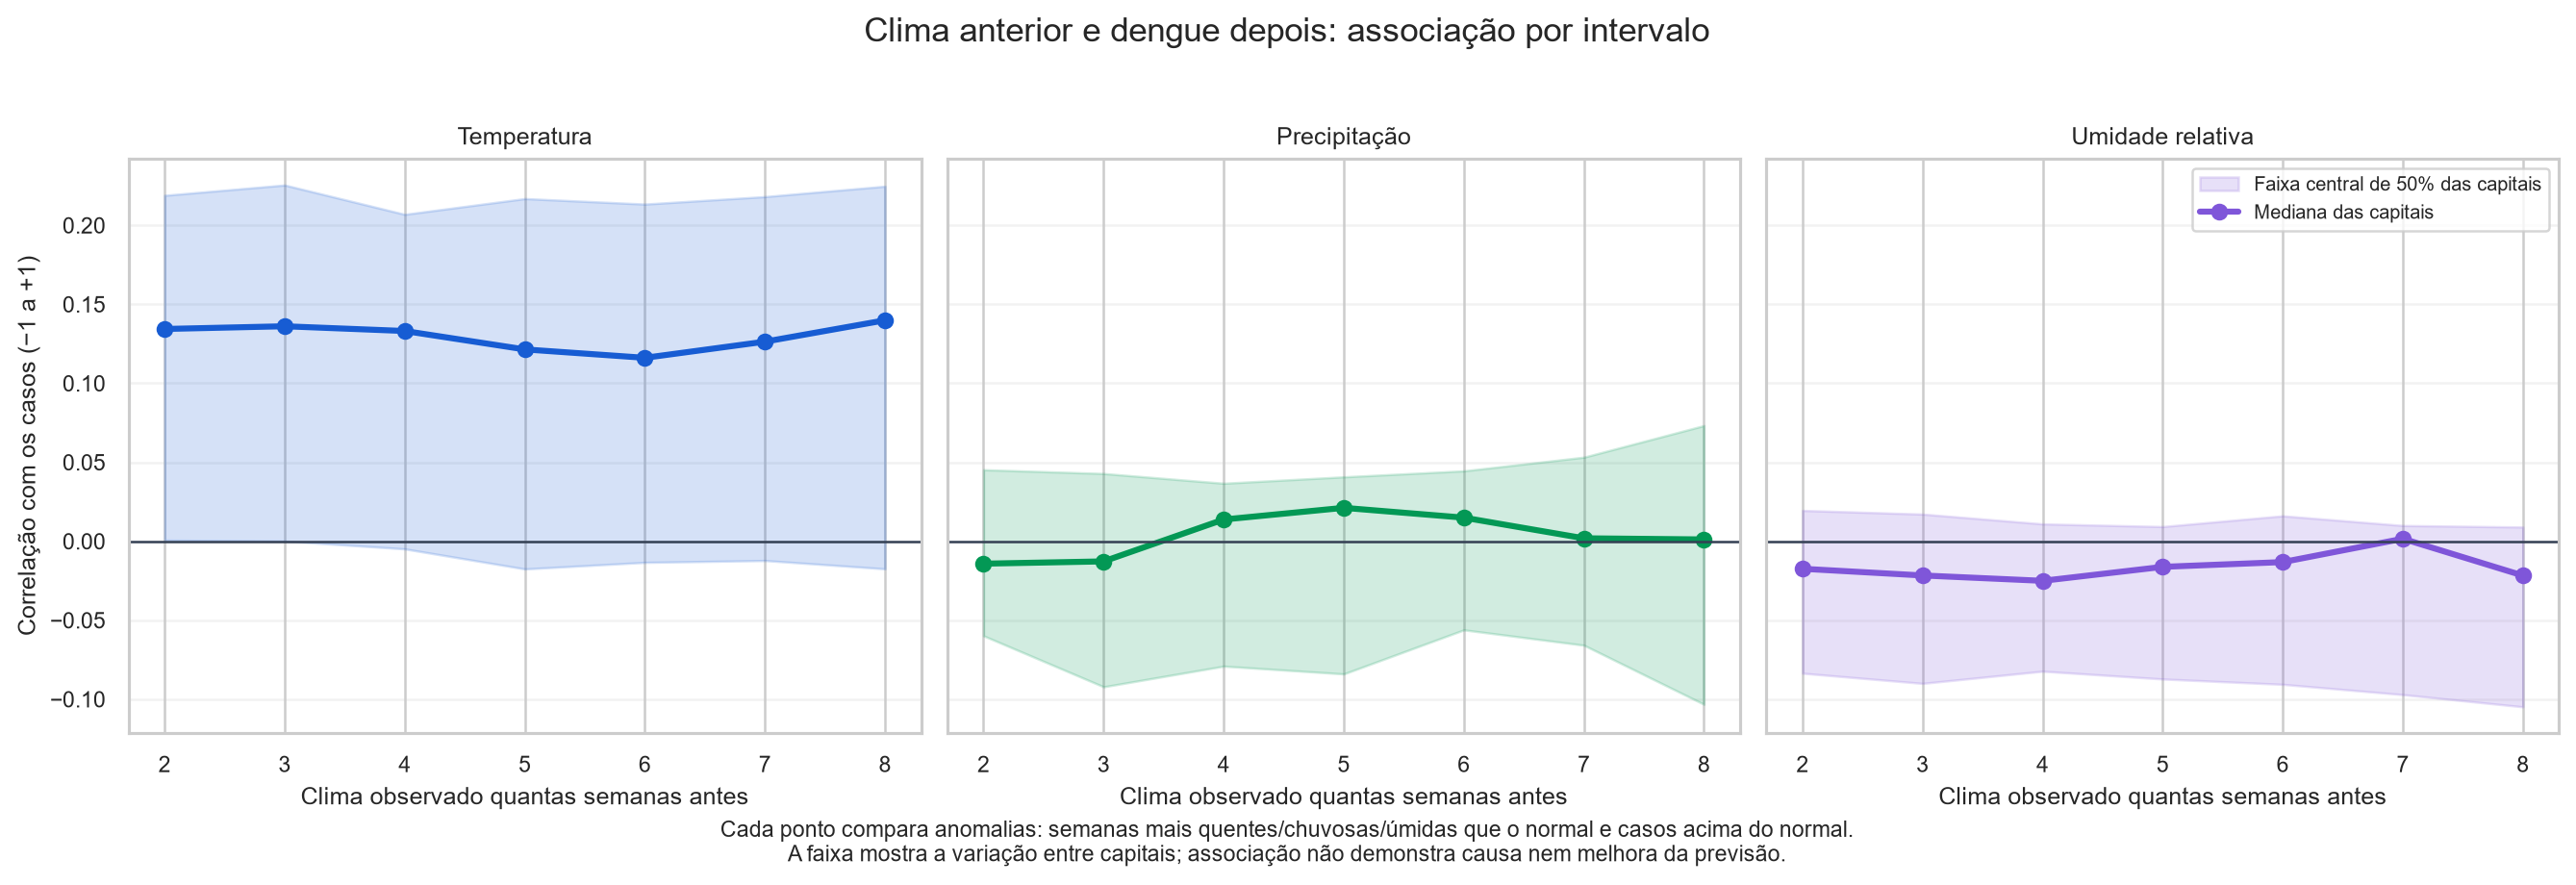

comparacao_series_clima_dengue.png


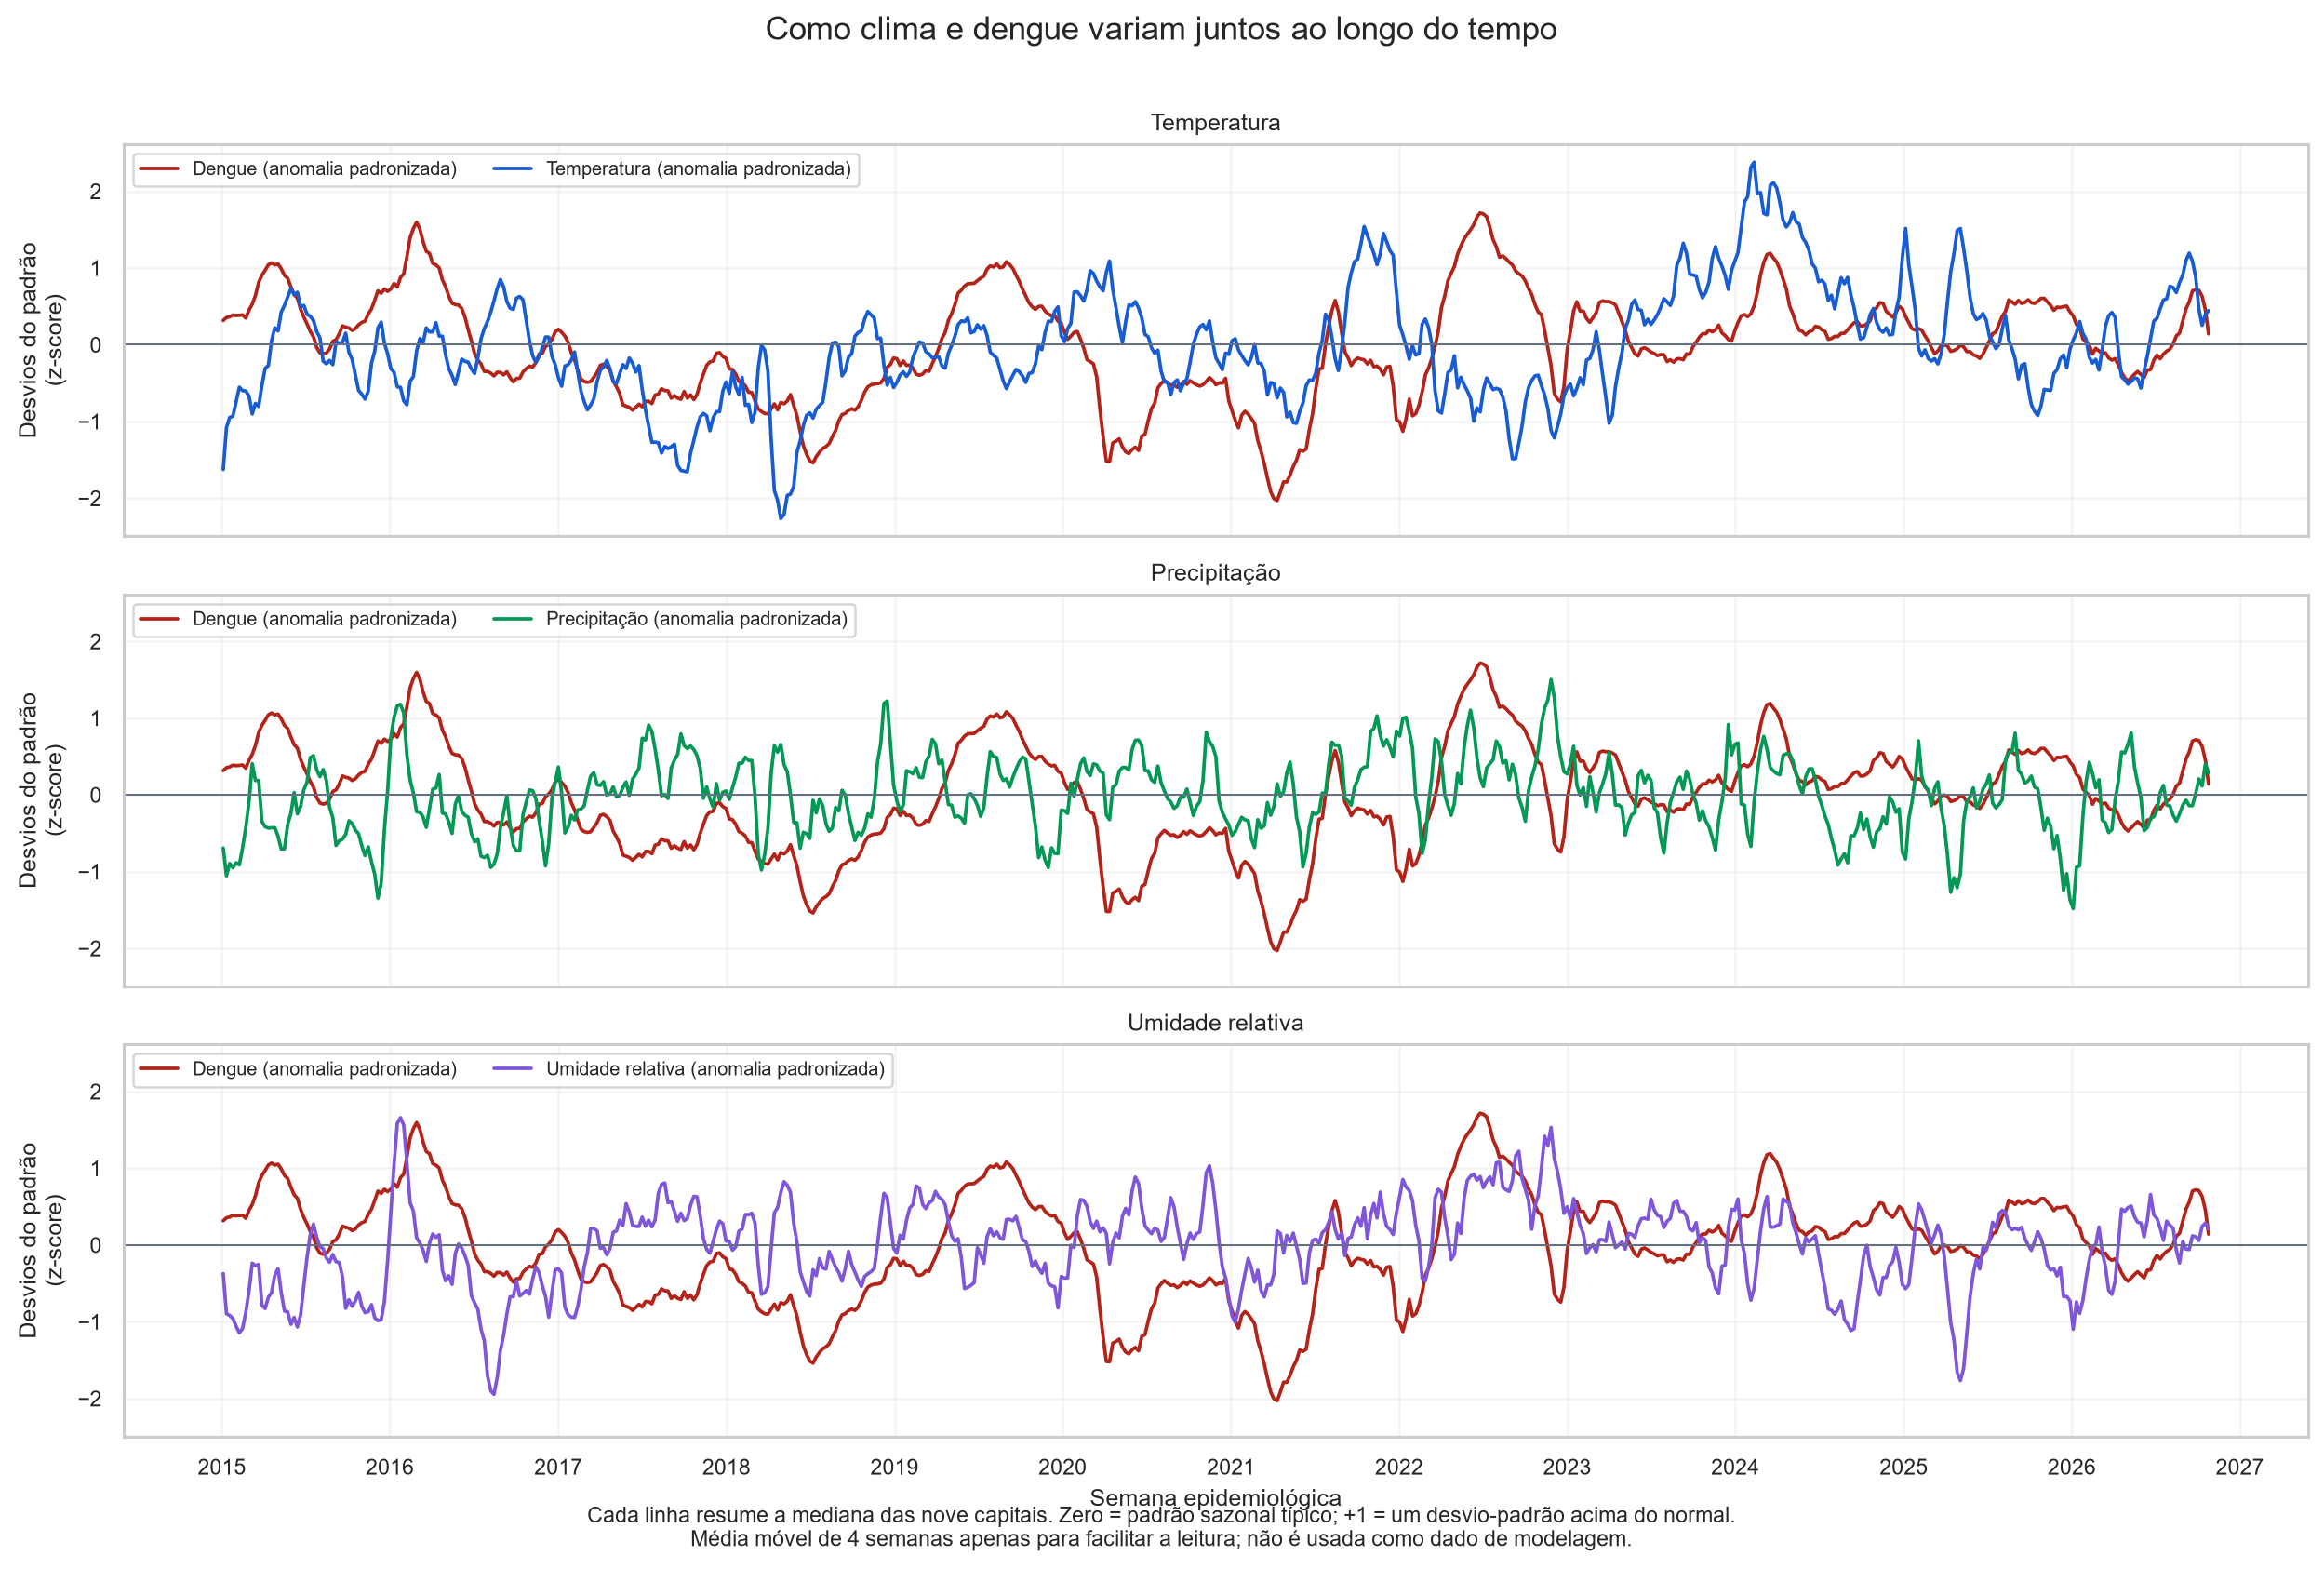

granger_p_ajustado.png


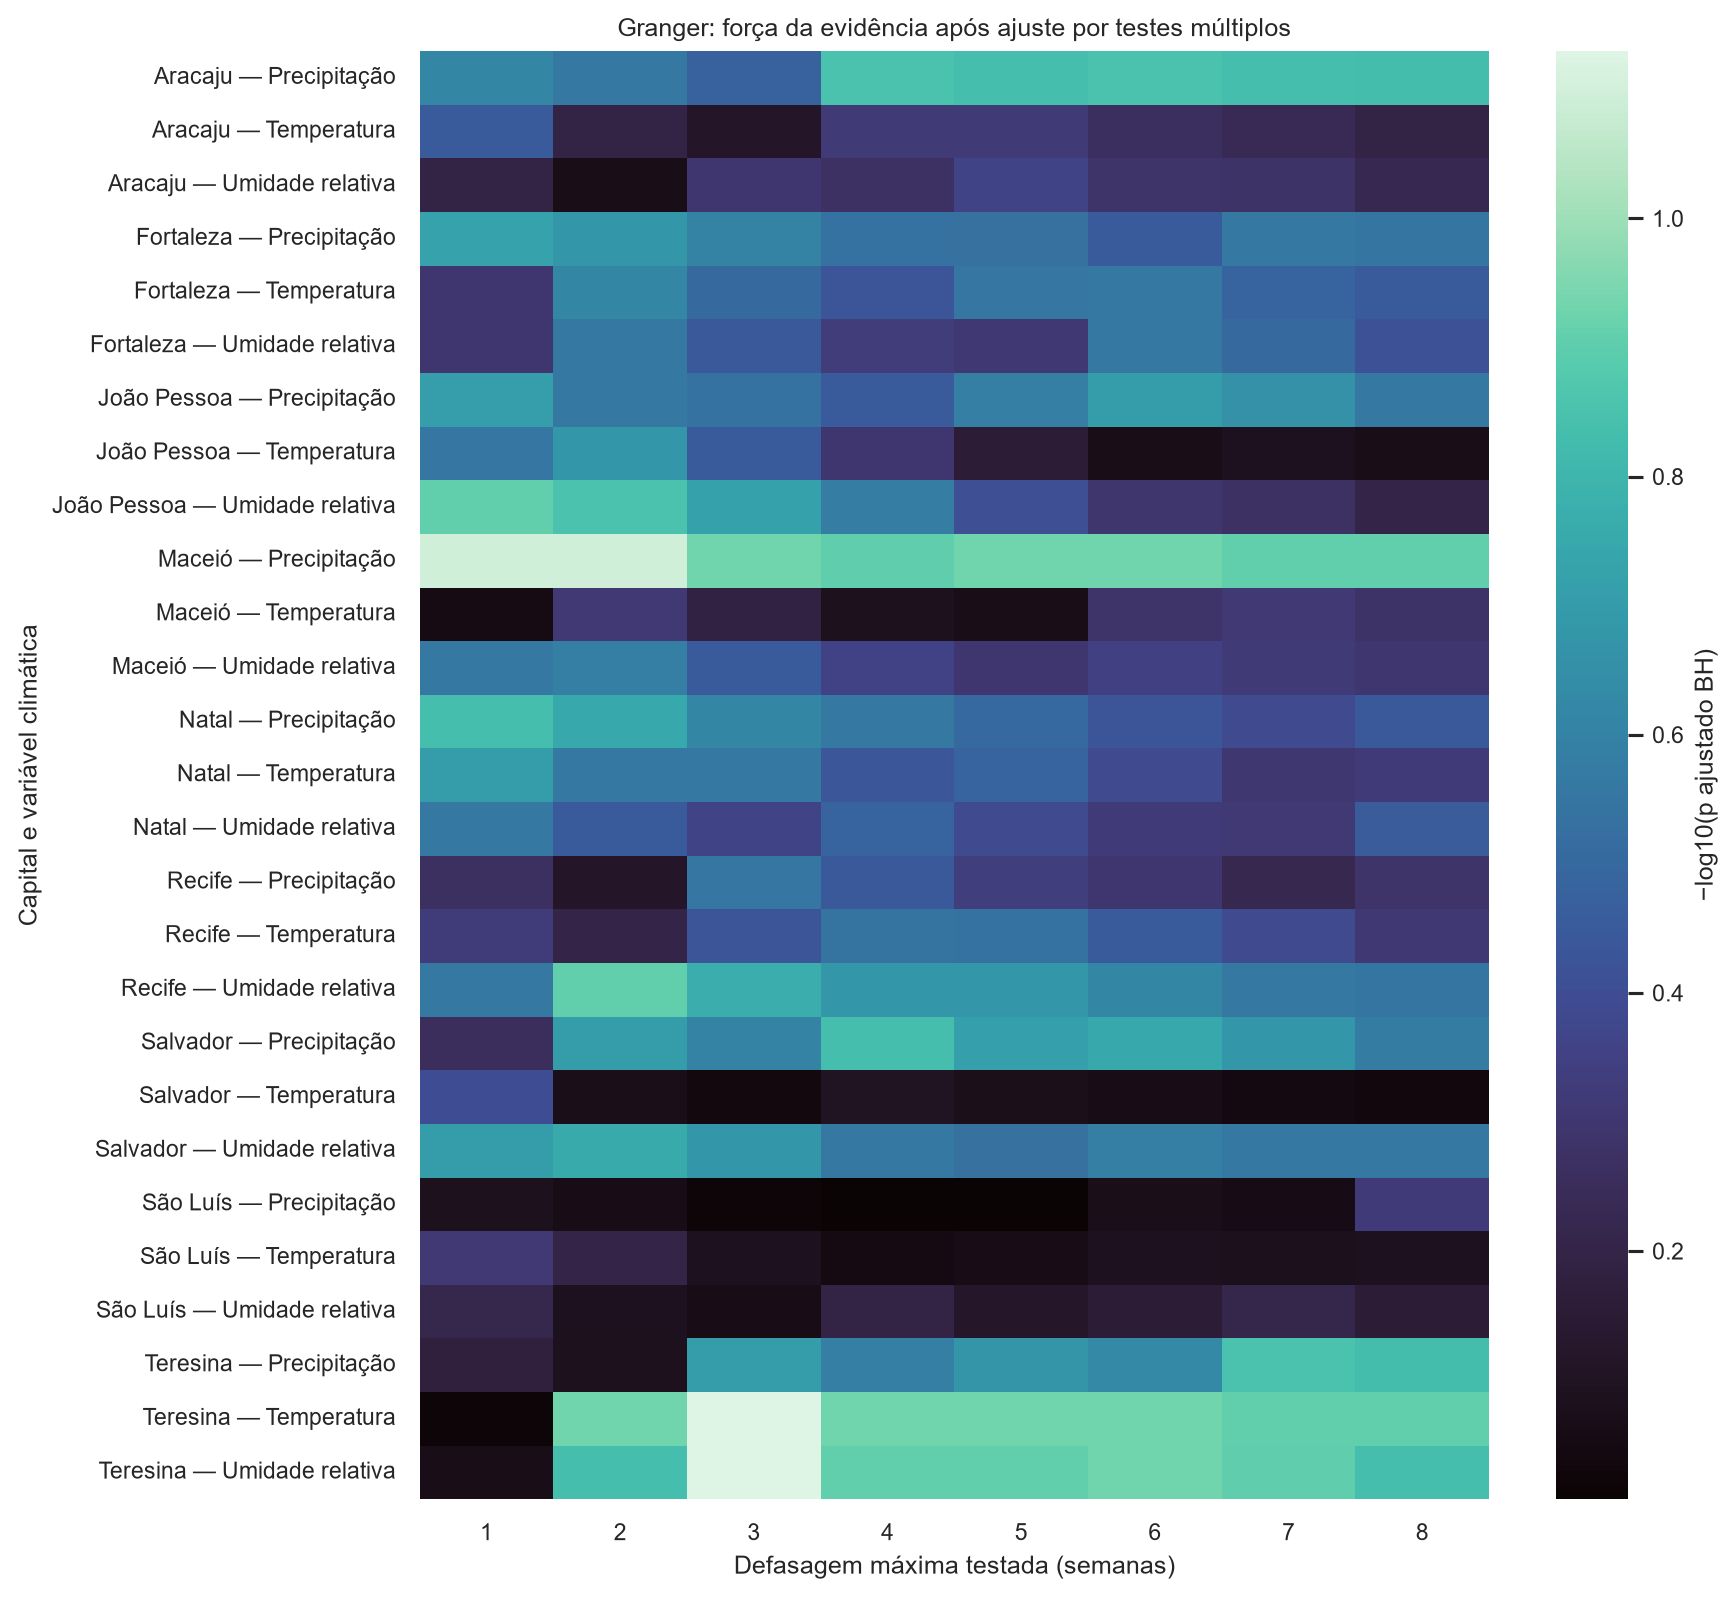

pearson_anomalias.png


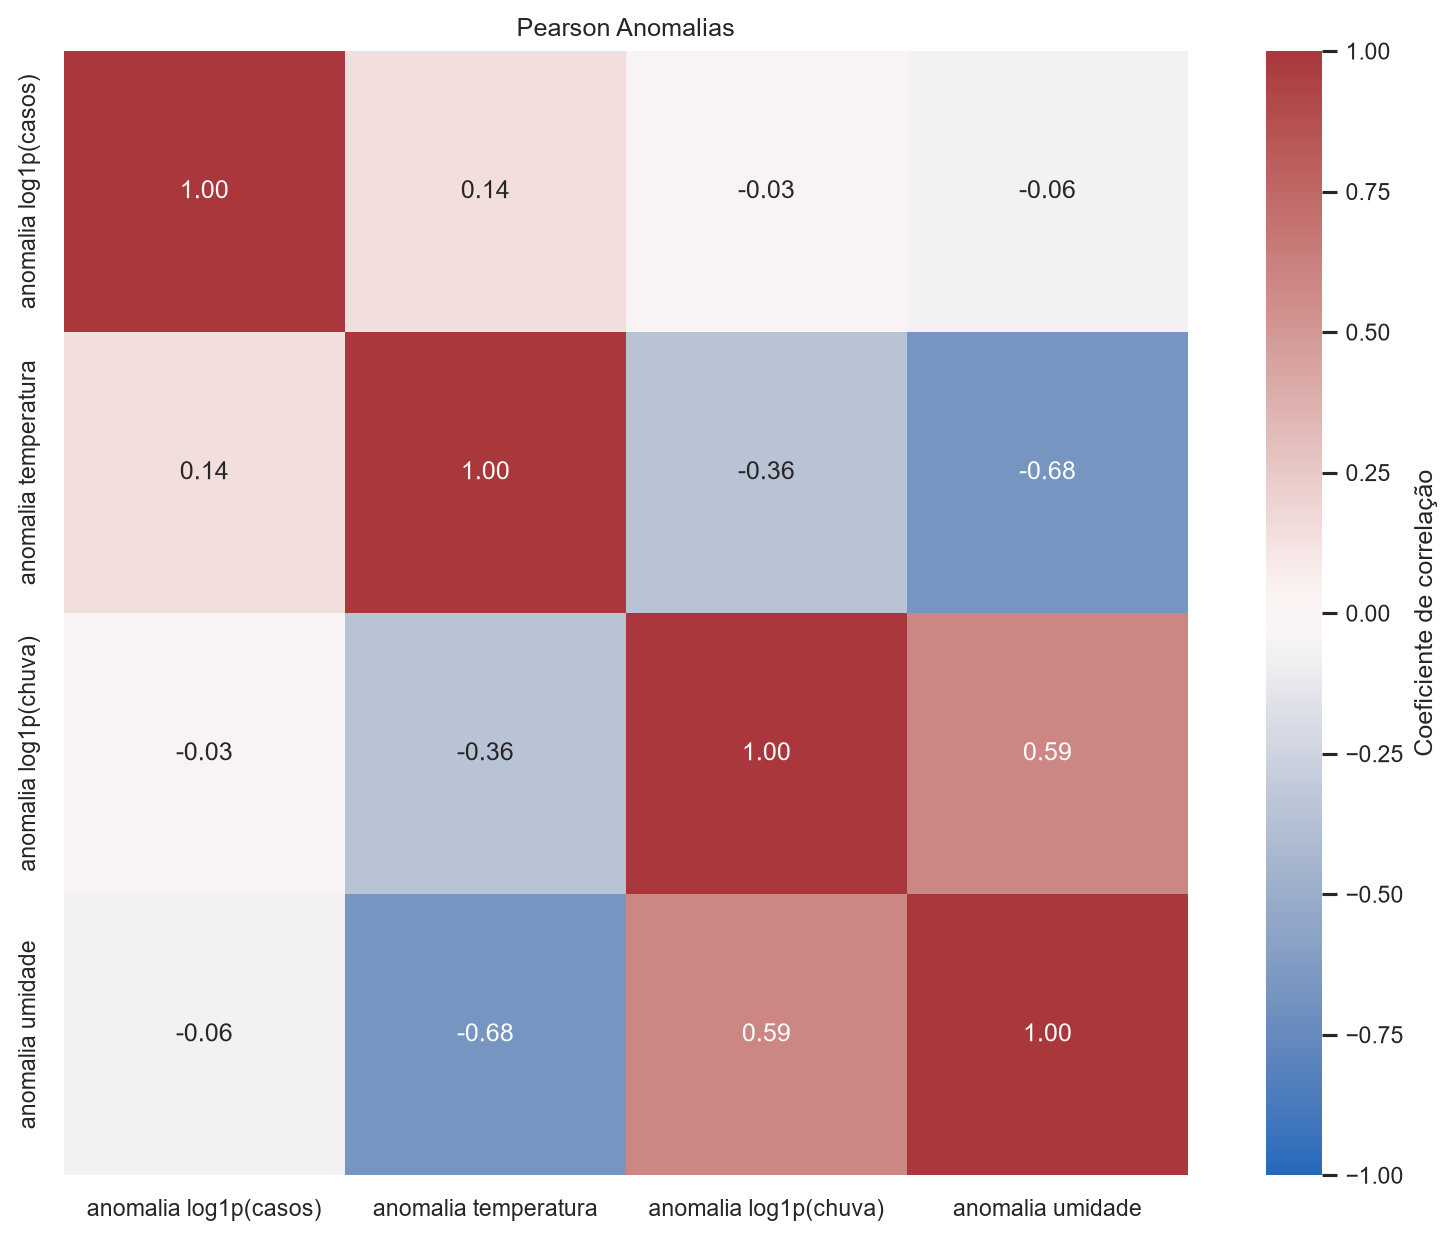

pearson_bruta.png


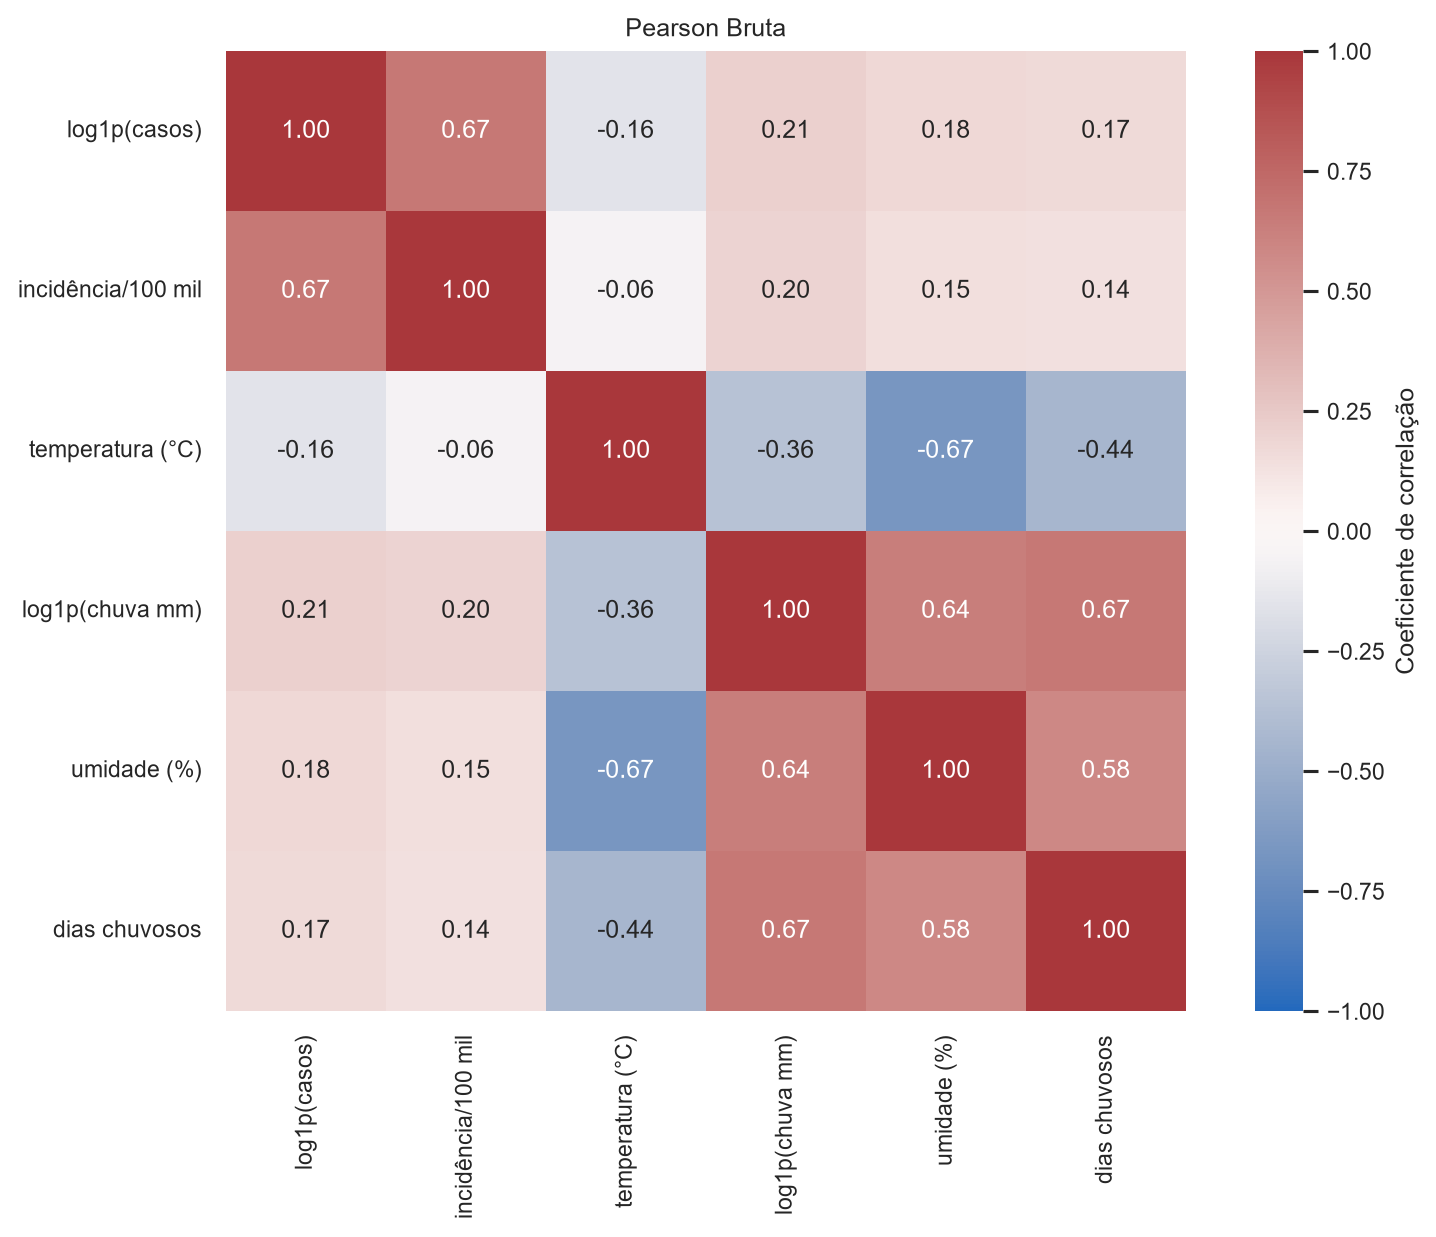

spearman_anomalias.png


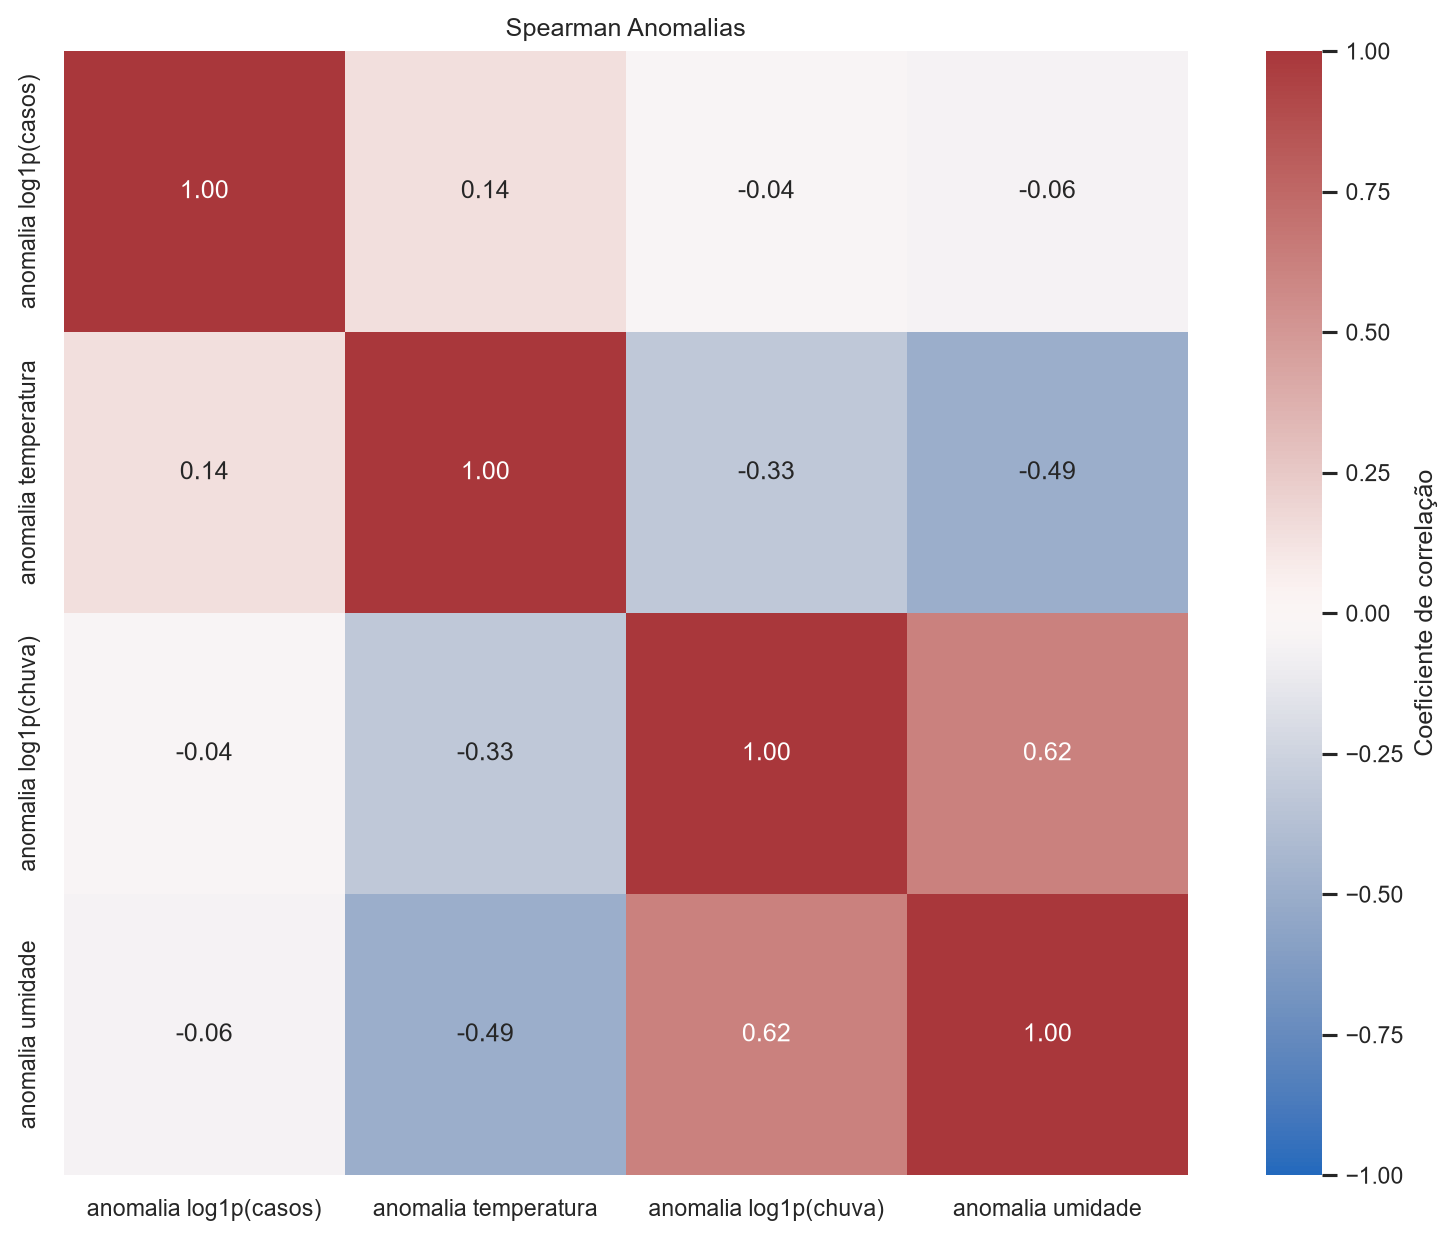

spearman_bruta.png


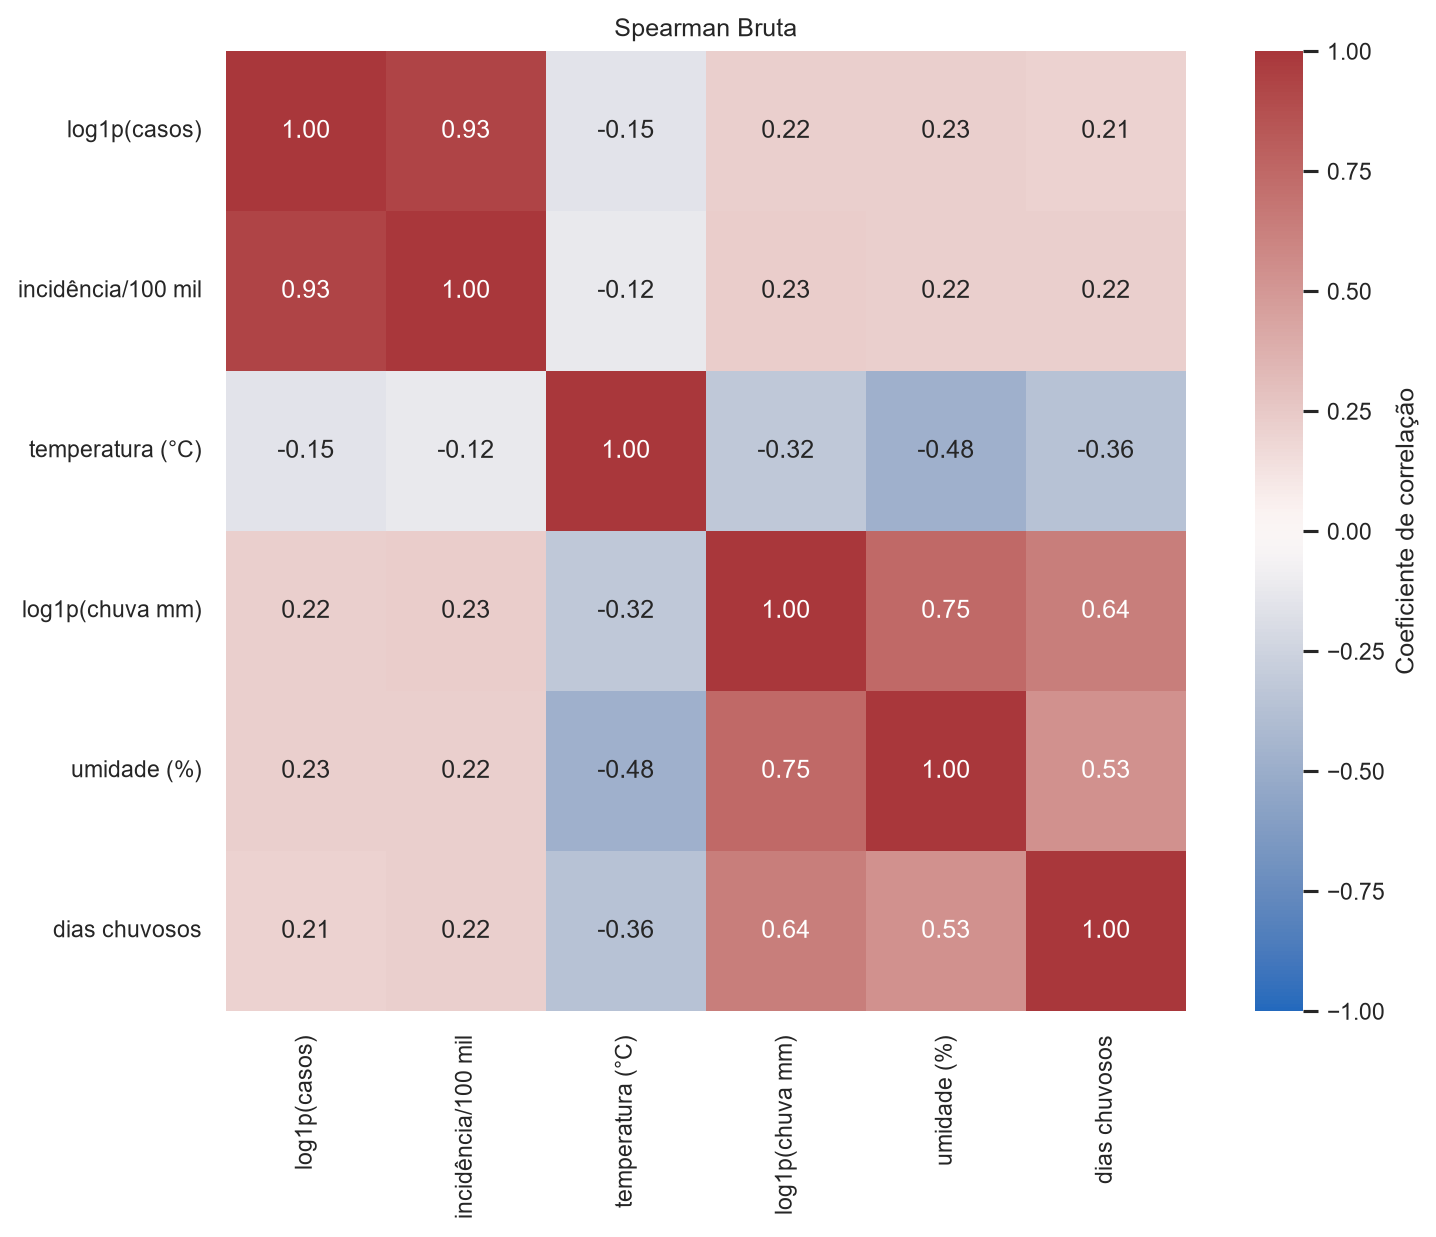

vif_top20.png


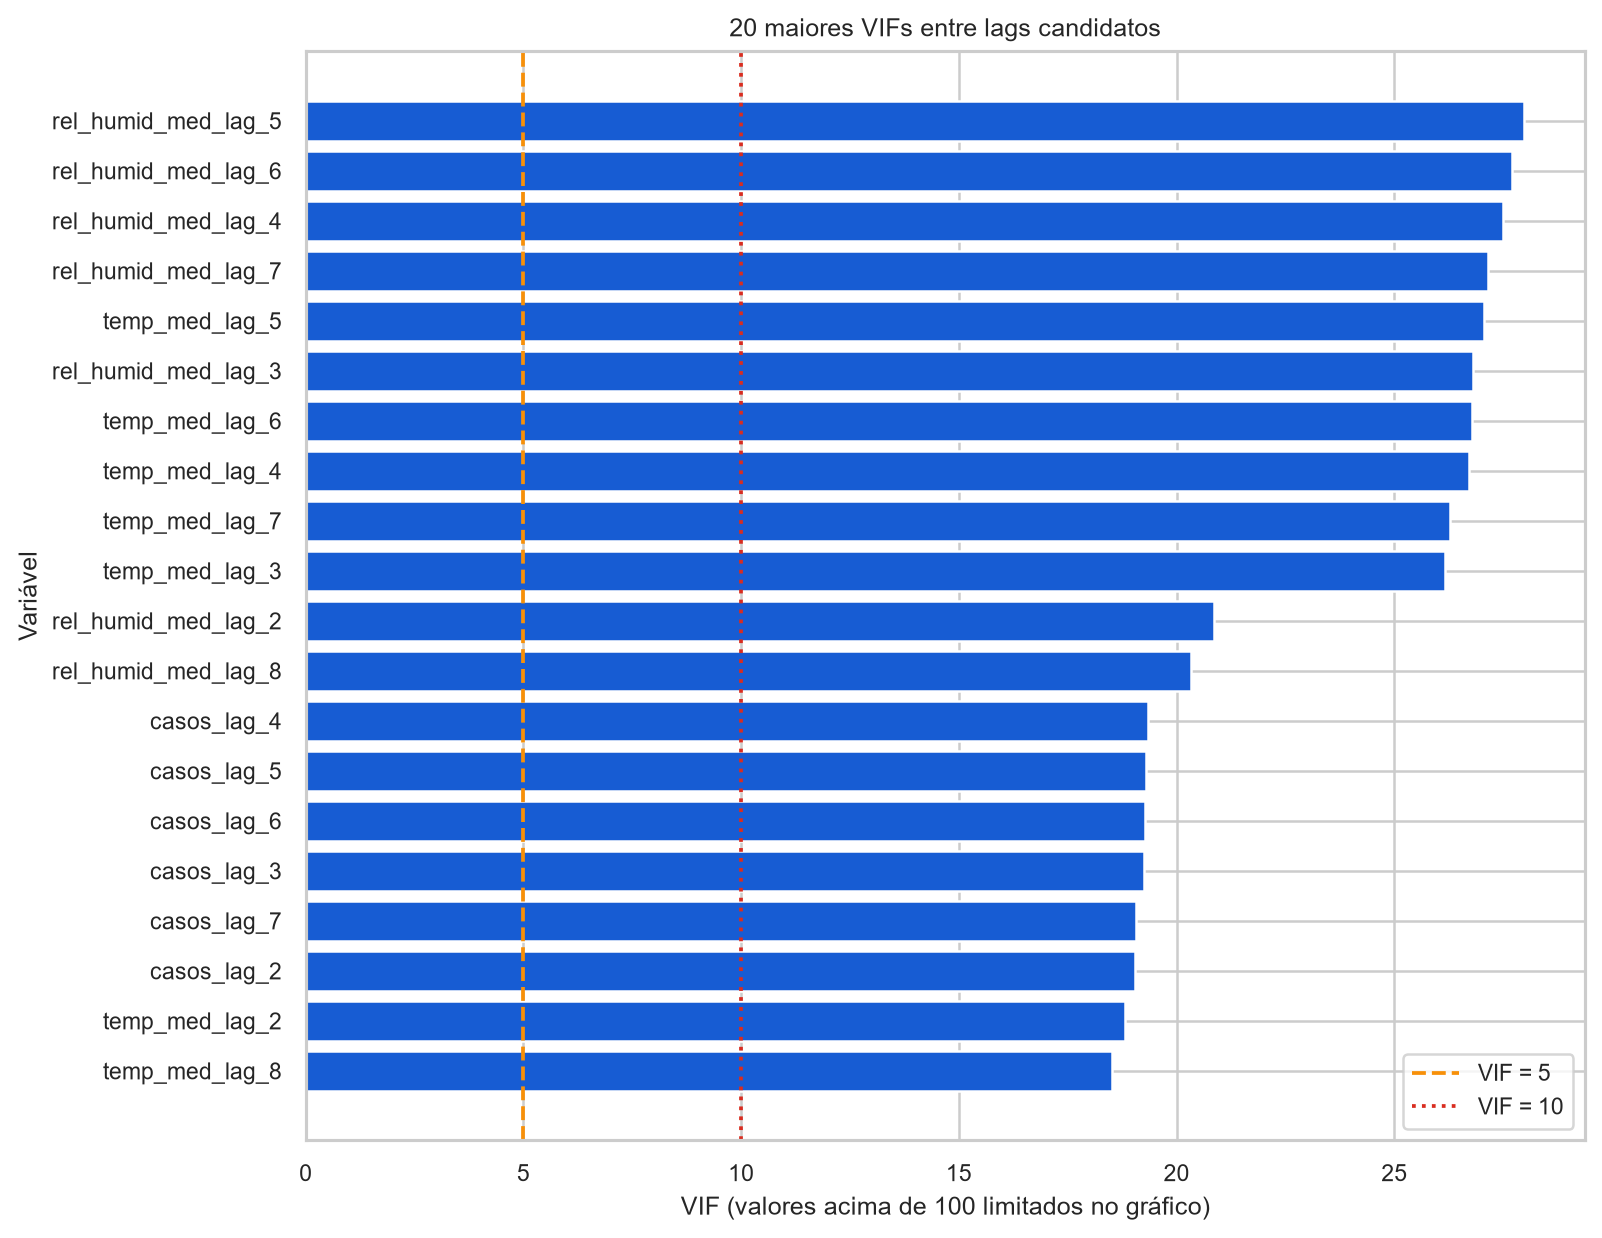

In [7]:
for p in sorted(FIG.glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))